# UK Cities Travelling Salesman Problem

## Setups and Data Loading

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import squareform, pdist

import warnings
warnings.filterwarnings('ignore')

In [44]:
raw = pd.read_csv("UK_Cities.csv")
raw.head()

,"City,Latitude,Longitude,Population"
0,"London,51.5074,-0.1278,8961989"
1,"Birmingham,52.4862,-1.8904,1153717"
2,"Leeds,53.8008,-1.5491,789194"
3,"Glasgow,55.8642,-4.2518,635640"
4,"Sheffield,53.3811,-1.4701,584853"


In [45]:
col_name = raw.columns[0]
new_cols = col_name.split(',')
data = raw[col_name].str.split(',', expand=True)
data.columns = new_cols

data['Latitude'] = pd.to_numeric(data['Latitude'])
data['Longitude'] = pd.to_numeric(data['Longitude'])
data = data.drop(columns='Population')
display(data.head())
data.info()

,City,Latitude,Longitude
0,London,51.5074,-0.1278
1,Birmingham,52.4862,-1.8904
2,Leeds,53.8008,-1.5491
3,Glasgow,55.8642,-4.2518
4,Sheffield,53.3811,-1.4701


<class 'pandas.DataFrame'>
RangeIndex: 49 entries, 0 to 48
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   City       49 non-null     str    
 1   Latitude   49 non-null     float64
 2   Longitude  49 non-null     float64
dtypes: float64(2), str(1)
memory usage: 1.3 KB


In [46]:
cities = data['City'].to_list()
city_index = {c: i for i, c in enumerate(cities)}   # O(1) lookup instead of cities.index()
coordinates = data[['Latitude', 'Longitude']].values
distance_matrix = squareform(pdist(coordinates, metric='euclidean'))

# # For display only; the algorithms use the numpy matrix directly
distance_data = pd.DataFrame(distance_matrix, index=cities, columns=cities)
distance_data.head()

,London,Birmingham,Leeds,Glasgow,Sheffield,Manchester,Bradford,Liverpool,Edinburgh,Bristol,...,Cambridge,Blackpool,Ipswich,Exeter,Woking,Crawley,Southend-on-Sea,St Helens,Southport,Barnsley
London,0.000000,2.016137,2.698106,5.999090,2.304891,2.892523,2.809846,3.437317,5.397470,2.460669,...,0.741191,3.713818,1.397167,3.496289,0.470871,0.402705,0.836586,3.254749,3.586735,2.452896
Birmingham,2.016137,0.000000,1.358182,4.121540,0.988685,1.055118,1.315340,1.436348,3.702071,1.245356,...,2.031712,1.756153,3.075855,2.413754,1.771323,2.190273,2.763210,1.285382,1.610244,1.141928
Leeds,2.698106,1.358182,0.000000,3.400325,0.427070,0.763768,0.210380,1.494919,2.705593,2.565975,...,2.310309,1.486694,3.216896,3.666145,2.672974,3.016624,3.190395,1.236692,1.465723,0.257110
Glasgow,5.999090,4.121540,3.400325,0.000000,3.728759,3.117287,3.239390,2.760264,1.067226,4.713175,...,5.702274,2.380731,6.611926,5.195636,5.857085,6.255553,6.576195,2.847038,2.543144,3.607671
Sheffield,2.304891,0.988685,0.427070,3.728759,0.000000,0.778907,0.504983,1.521745,3.093287,2.227390,...,1.979053,1.625284,2.939680,3.368864,2.255364,2.609179,2.848095,1.268203,1.559385,0.171912


## Helper functions

In [47]:
def _resolve_path(path):
    """Standardize path into a list of indices."""
    # Standardize the path by converting city names (str) to matrix indices (int)
    resolved_path = [city_index[node] if isinstance(node, str) else int(node) for node in path]
    # Remove duplicate end node if the path is closed
    if len(resolved_path) > 1 and resolved_path[0] == resolved_path[-1]:
        resolved_path = resolved_path[:-1]
    
    return resolved_path


def get_total_distance(path, distance_matrix):
    """Compute the total distance of a closed tour (vectorized with numpy)."""
    p = np.array(_resolve_path(path))
    return distance_matrix[p, np.roll(p, -1)].sum()


def plot_path(coordinates, path, title):
    """Plot the given path on a 2D map; the starting city is marked with a red star."""
    resolved_path = _resolve_path(path)
    ordered = coordinates[resolved_path + [resolved_path[0]]]
    start = coordinates[resolved_path[0]]

    plt.figure(figsize=(10, 8))
    plt.plot(ordered[:, 1], ordered[:, 0], marker='o', zorder=1)
    # Highlight the starting city
    plt.scatter(start[1], start[0], marker='*', s=300, c='red',
                edgecolors='black', zorder=3, label=f"Start: {cities[resolved_path[0]]}")
    for i, idx in enumerate(resolved_path):
        plt.text(coordinates[idx][1], coordinates[idx][0], f"{i + 1}-{cities[idx]}", fontsize=7)
    plt.title(title)
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.grid(True)
    plt.legend()
    plt.show()

## Algorithms

### Nearest Neighbour Heuristics (NHH)

In [48]:
def nearest_neighbour(distance_matrix, start=0):
    """Build a tour with the nearest neighbour heuristic, beginning at index `start`."""
    n = len(distance_matrix)
    current = start
    visited = np.zeros(n, dtype=bool)
    path = []
    for _ in range(n):
        path.append(current)
        visited[current] = True
        if len(path) == n:
            break
        d = np.where(visited, np.inf, distance_matrix[current])
        current = int(d.argmin())
    return path

Total distance: 37.49


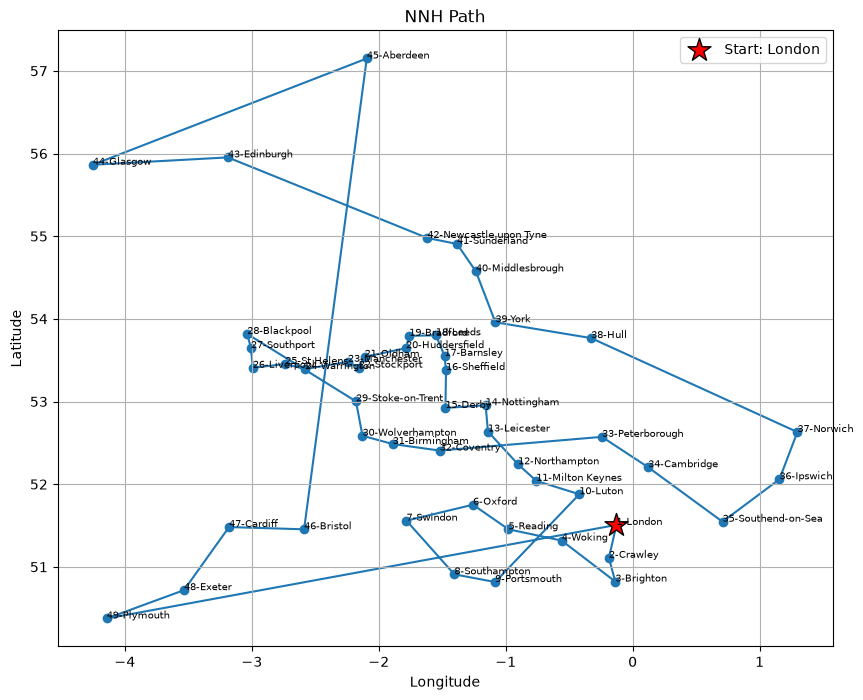

In [49]:
nnh_path = nearest_neighbour(distance_matrix)
print(f"Total distance: {get_total_distance(nnh_path, distance_matrix):.2f}")
plot_path(coordinates, nnh_path, title="NNH Path")

### 2-Opt Improvement Heuristic

In [50]:
def two_opt(path, distance_matrix):
    """Improve a tour with 2-opt, using O(1) delta evaluation until no improving swap remains."""
    d = distance_matrix
    path = list(path)
    n = len(path)
    improved = True
    while improved:
        improved = False
        for i in range(n - 2):
            for j in range(i + 2, n):
                if i == 0 and j == n - 1:
                    continue
                a, b = path[i], path[i + 1]
                c, e = path[j], path[(j + 1) % n]
                if d[a, c] + d[b, e] < d[a, b] + d[c, e] - 1e-10:
                    path[i + 1:j + 1] = path[i + 1:j + 1][::-1]
                    improved = True
    return path

Total distance: 31.57


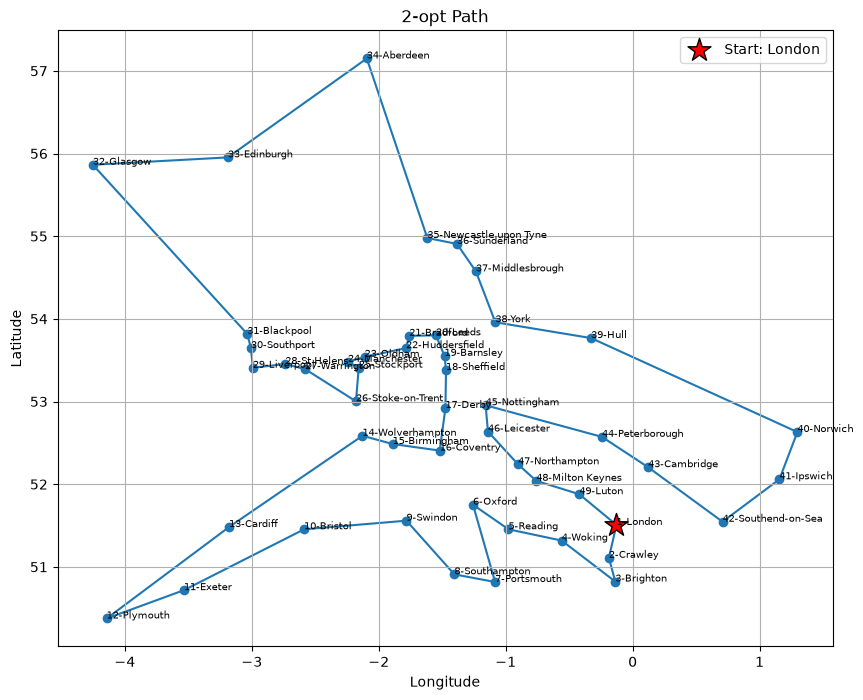

In [51]:
opt2_path = two_opt(nnh_path, distance_matrix)
print(f"Total distance: {get_total_distance(opt2_path, distance_matrix):.2f}")
plot_path(coordinates, opt2_path, title="2-opt Path")

### 3-Opt Improvement Heuristic

In [52]:
def three_opt(path, distance_matrix):
    """Improve a tour with 3-opt (all 7 reconnections), using O(1) delta evaluation until no improving move remains."""
    d = distance_matrix
    path = list(path)
    n = len(path)
    improved = True
    while improved:
        improved = False
        for i in range(n - 2):
            for j in range(i + 1, n - 1):
                for k in range(j + 1, n):
                    A, B = path[i], path[i + 1]
                    C, D_ = path[j], path[j + 1]
                    E, G = path[k], path[(k + 1) % n]
                    old = d[A, B] + d[C, D_] + d[E, G]
                    moves = (
                        (d[A, C]  + d[B, D_] + d[E, G],  0),
                        (d[A, B]  + d[C, E]  + d[D_, G], 1),
                        (d[A, C]  + d[B, E]  + d[D_, G], 2),
                        (d[A, D_] + d[E, B]  + d[C, G],  3),
                        (d[A, D_] + d[E, C]  + d[B, G],  4),
                        (d[A, E]  + d[D_, B] + d[C, G],  5),
                        (d[A, E]  + d[D_, C] + d[B, G],  6),
                    )
                    new, m = min(moves)
                    if new < old - 1e-10:
                        s1, s2, s3, tail = path[:i+1], path[i+1:j+1], path[j+1:k+1], path[k+1:]
                        mid = (s2[::-1] + s3, s2 + s3[::-1], s2[::-1] + s3[::-1],
                               s3 + s2, s3 + s2[::-1], s3[::-1] + s2,
                               s3[::-1] + s2[::-1])[m]
                        path = s1 + mid + tail
                        improved = True
    return path

Total distance: 30.93


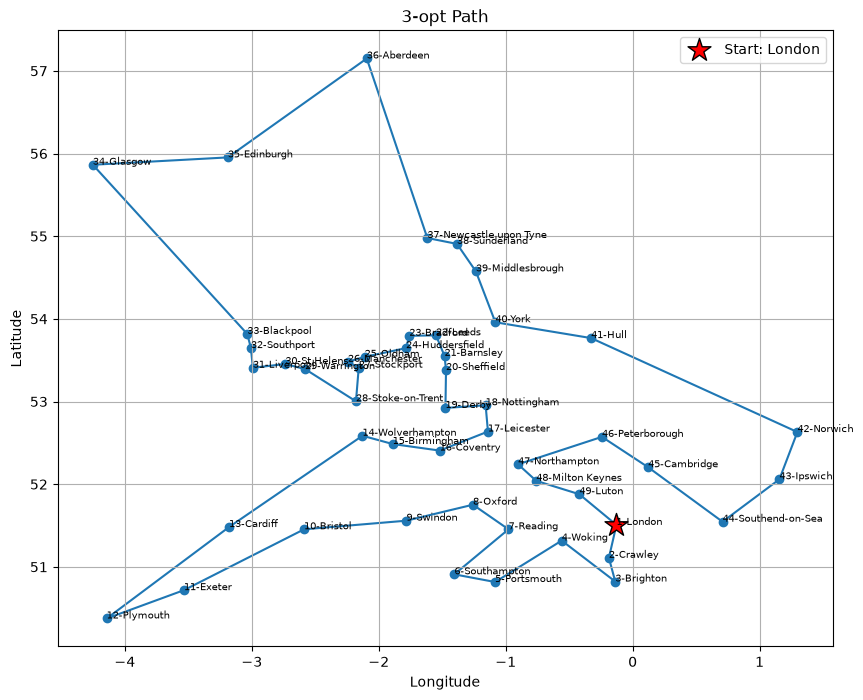

In [53]:
opt3_path = three_opt(opt2_path, distance_matrix)
print(f"Total distance: {get_total_distance(opt3_path, distance_matrix):.2f}")
plot_path(coordinates, opt3_path, title="3-opt Path")

### Optimal Solution with CP-SAT

In [54]:
from ortools.sat.python import cp_model

def solve_tsp_exact(distance_matrix, hint_path=None, scale=10_000, time_limit=300, workers=8):
    """Solve the TSP to proven optimality with CP-SAT (AddCircuit)."""
    n = len(distance_matrix)
    cost = np.rint(distance_matrix * scale).astype(np.int64)

    model = cp_model.CpModel()
    arcs, lit = [], {}
    for i in range(n):
        for j in range(n):
            if i != j:
                lit[i, j] = model.NewBoolVar(f"x_{i}_{j}")
                arcs.append((i, j, lit[i, j]))
    model.AddCircuit(arcs)                      # exactly one Hamiltonian cycle
    model.Minimize(sum(int(cost[i, j]) * lit[i, j] for (i, j) in lit))

    if hint_path is not None:                   # warm start from a heuristic tour
        succ = {hint_path[k]: hint_path[(k + 1) % n] for k in range(n)}
        for (i, j), v in lit.items():
            model.AddHint(v, int(succ[i] == j))

    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = time_limit
    solver.parameters.num_workers = workers
    status = solver.Solve(model)

    if status not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        return None, None, solver.StatusName(status), None
    succ = {i: j for (i, j), v in lit.items() if solver.Value(v)}
    path, cur = [], 0
    for _ in range(n):
        path.append(cur)
        cur = succ[cur]
    length = distance_matrix[path, np.roll(path, -1)].sum()
    return path, length, solver.StatusName(status), solver.BestObjectiveBound() / scale

Status: OPTIMAL | Total distance: 30.6805 | Lower bound: 30.6806
3-opt gap to optimal: 0.83%


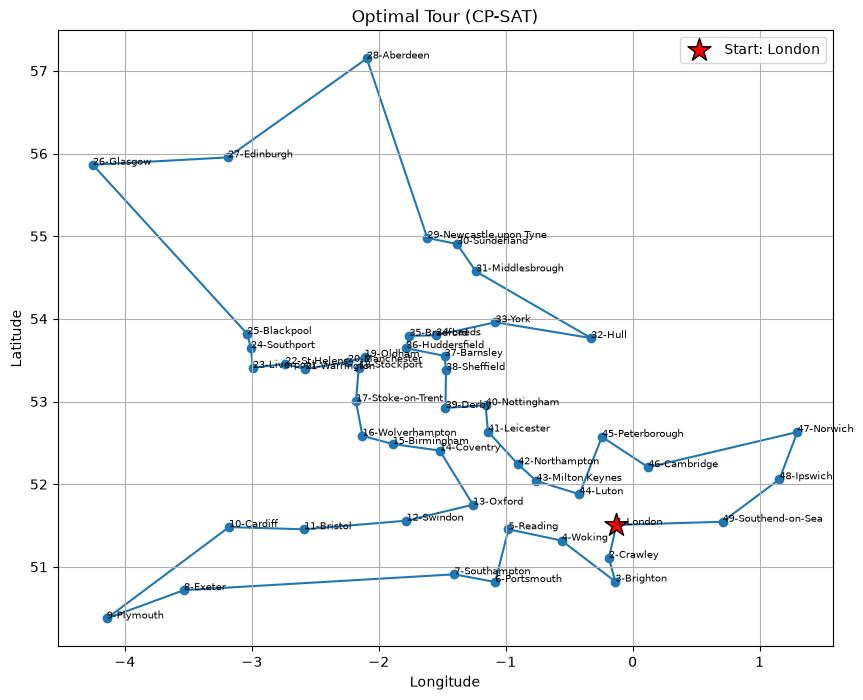

In [55]:
opt_path, opt_len, status, bound = solve_tsp_exact(distance_matrix, hint_path=opt3_path)
print(f"Status: {status} | Total distance: {opt_len:.4f} | Lower bound: {bound:.4f}")
print(f"3-opt gap to optimal: {100 * (get_total_distance(opt3_path, distance_matrix) - opt_len) / opt_len:.2f}%")
plot_path(coordinates, opt_path, title="Optimal Tour (CP-SAT)")